# Домашнее задание. Модуль 1. Искусственный нейрон и перцептрон

Сосновский Егор, М26-515

## 1. Линейно разделимые точки

### Условие

Возьмите двумерные точки из практического ноутбука модуля 1. Подберите веса $w$ и смещение $b$ для максимально возможной точности. Постройте график с точками двух классов и решающей границей.

### Решение

беру 60 точек из раздела 5 практического ноутбука. seed 42 и порядок генерации сохраняю. перцептрон считает $S=w_1x_1+w_2x_2+b$ и выдаёт класс 1 при $S \ge 0$, иначе класс 0.

сначала меняю по одному параметру и сравниваю точность с исходной. для итогового варианта беру $w=(1,1)$ и считаю $x_1+x_2$ у каждой точки. максимум класса 0 меньше минимума класса 1, поэтому ставлю порог посередине между ними. смещение равно порогу с обратным знаком, потому что граница задана уравнением $x_1+x_2+b=0$.

### Код

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import Markdown, display


def predict(points, weights, bias):
    # точка на самой границе относится к классу 1
    scores = points @ weights + bias
    return (scores >= 0).astype(int)

In [2]:
# точки из раздела 5 практического ноутбука
np.random.seed(42)
class_0 = np.random.normal(loc=[-4, 0], scale=1.2, size=(30, 2))
class_1 = np.random.normal(loc=[2, 1], scale=0.7, size=(30, 2))

X = np.vstack([class_0, class_1])
y_true = np.array([0] * len(class_0) + [1] * len(class_1))


w_linear = np.array([1.0, 1.0])
projection = X @ w_linear
max_class_0 = projection[y_true == 0].max()
min_class_1 = projection[y_true == 1].min()

# ставим порог в середину промежутка между классами
threshold = (max_class_0 + min_class_1) / 2
b_linear = -threshold
pred_linear = predict(X, w_linear, b_linear)


def plot_boundary(points, labels, weights, bias, title):
    fig, ax = plt.subplots(figsize=(6.4, 5.1), layout='constrained')

    for label, marker, color in [(0, 'o', '#245B8A'), (1, '^', '#A94C15')]:
        group = points[labels == label]
        ax.scatter(group[:, 0], group[:, 1], marker=marker, color=color,
                   s=44, label=f'Класс {label}', zorder=3)

    x_min, y_min = points.min(axis=0) - 0.4
    x_max, y_max = points.max(axis=0) + 0.4
    x_values = np.array([x_min, x_max])

    # выражаем x2 из уравнения границы S = 0
    boundary = -(weights[0] * x_values + bias) / weights[1]
    ax.plot(x_values, boundary, '--', color='#202020', label='Граница S = 0')
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max),
           xlabel='$x_1$', ylabel='$x_2$', title=title)
    ax.set_aspect('equal')
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

### Проверка

Точек класса 0: 30
Точек класса 1: 30
Максимум x1 + x2 в классе 0: -1.184023
Минимум x1 + x2 в классе 1: 1.388221

Исходный вариант: w = (1.0, 1.0), b = 0.000000, точность 100% (60 из 60)
Изменён второй вес: w = (1.0, 0.5), b = 0.000000, точность 100% (60 из 60)
Изменено смещение: w = (1.0, 1.0), b = -0.500000, точность 100% (60 из 60)
Порог между классами: w = (1.0, 1.0), b = -0.102099, точность 100% (60 из 60)


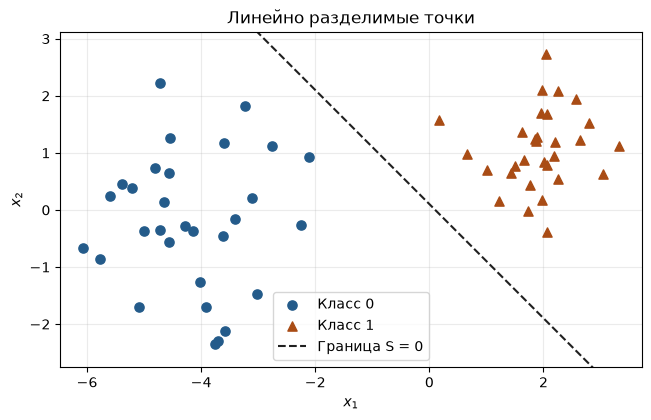

In [3]:
# сначала меняем один вес, затем отдельно меняем смещение
variants = [
    ('Исходный вариант', np.array([1.0, 1.0]), 0.0),
    ('Изменён второй вес', np.array([1.0, 0.5]), 0.0),
    ('Изменено смещение', np.array([1.0, 1.0]), -0.5),
    ('Порог между классами', w_linear, b_linear),
]

print(f'Точек класса 0: {np.sum(y_true == 0)}')
print(f'Точек класса 1: {np.sum(y_true == 1)}')
print(f'Максимум x1 + x2 в классе 0: {max_class_0:.6f}')
print(f'Минимум x1 + x2 в классе 1: {min_class_1:.6f}')
print()

for name, weights, bias in variants:
    predictions = predict(X, weights, bias)
    correct = np.count_nonzero(predictions == y_true)
    print(f'{name}: w = {tuple(weights.tolist())}, b = {bias:.6f}, '
          f'точность {correct / len(y_true):.0%} ({correct} из {len(y_true)})')

assert max_class_0 < threshold < min_class_1
assert np.array_equal(pred_linear, y_true)
plot_boundary(X, y_true, w_linear, b_linear, 'Линейно разделимые точки')

## 2. Перцептрон на XOR

### Условие

Примените тот же подход к XOR. Рассчитайте точность и объясните, почему один перцептрон не может правильно разделить все четыре точки.

### Решение

у XOR класс 1 получается, когда входы различаются. беру те же веса $(1,1)$ и ставлю порог $0{,}5$. суммы у точек $(0,0)$, $(0,1)$, $(1,0)$ и $(1,1)$ равны $0,1,1,2$. при таком пороге верно определяются первые три точки.

чтобы все точки классифицировались правильно, для точек класса 0 нужны условия $b<0$ и $w_1+w_2+b<0$. складываю их и получаю $w_1+w_2+2b<0$. для точек класса 1 нужны условия $w_1+b\ge0$ и $w_2+b\ge0$. их сумма даёт $w_1+w_2+2b\ge0$. одна и та же сумма не может одновременно удовлетворять этим условиям, поэтому 4 правильных ответа невозможны.

### Код

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
w_xor = np.array([1.0, 1.0])
b_xor = -0.5

scores_xor = X_xor @ w_xor + b_xor
pred_xor = predict(X_xor, w_xor, b_xor)
correct_xor = np.count_nonzero(pred_xor == y_xor)

### Проверка

Веса: (1.0, 1.0), смещение: -0.5
Точность: 75% (3 из 4)


| Точка | S | Истинный класс | Предсказание |
|---|---:|---:|---:|
| (0, 0) | -0.5 | 0 | 0 |
| (0, 1) | 0.5 | 1 | 1 |
| (1, 0) | 0.5 | 1 | 1 |
| (1, 1) | 1.5 | 0 | 1 |

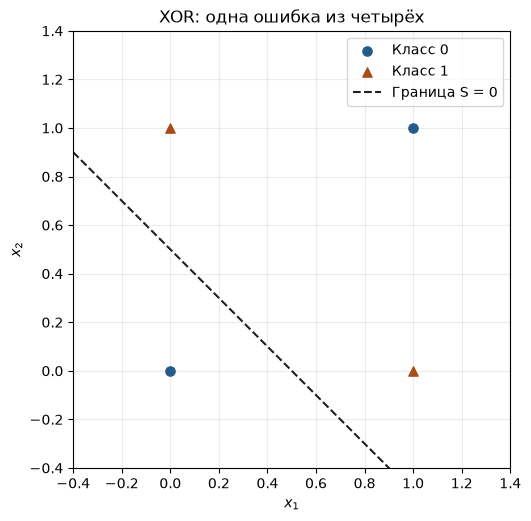

In [5]:
print(f'Веса: {tuple(w_xor.tolist())}, смещение: {b_xor}')
print(f'Точность: {correct_xor / len(y_xor):.0%} ({correct_xor} из {len(y_xor)})')

rows = [
    '| Точка | S | Истинный класс | Предсказание |',
    '|---|---:|---:|---:|',
]
for point, score, expected, predicted in zip(X_xor, scores_xor, y_xor, pred_xor):
    rows.append(f'| {tuple(point.tolist())} | {score:.1f} | {expected} | {predicted} |')

display(Markdown('\n'.join(rows)))
assert correct_xor == 3
plot_boundary(X_xor, y_xor, w_xor, b_xor, 'XOR: одна ошибка из четырёх')

## Вывод

На линейно разделимых данных веса `(1, 1)` и смещение около -0,102099 дали 100% точности, правильно определены все 60 точек. Порог между классами проходит посередине между наибольшей суммой признаков класса 0 и наименьшей суммой класса 1. На XOR те же веса и смещение −0,5 дали 75% точности, ошибка получилась в точке (1, 1). Это максимум для одного перцептрона, поскольку четыре правильных ответа требуют одновременно двух несовместимых условий для весов и смещения.